# Introduction

In this tutorial, we will use the **UNI model** from [MahmoodLab](https://github.com/mahmoodlab/UNI) (follow the Installation steps), a self-supervised vision transformer trained on histology slides, to extract **patch-level feature embeddings** from Whole Slide Images (WSIs).

The steps we will follow are:

1. **Load** the pretrained UNI model and its checkpoint weights.
2. **Tokenize** the WSI into small, non-overlapping patches of size **224×224 pixels**.
3. **Save** each patch image and record its spatial location (X, Y coordinates) on the original WSI.
4. **Feed** the patches through the pretrained UNI model to extract deep **feature embeddings**.
5. **Link** each embedding with its spatial metadata (Slide ID, Patch ID, coordinates).
6. **Save** the final dataset for downstream spatial analysis tasks.

---

By following this process, we create a compact and meaningful representation of very large WSIs, which can be easily used for downstream tasks.


# Imports and Environment Setup

In this section, we import the necessary libraries and set up the environment.

- **PyTorch** (`torch`) and **TorchVision**: for deep learning operations and image handling.
- **Pandas**, **NumPy**: for working with tabular data and arrays.
- **PIL** (`Image`): for opening and processing images.
- **Tifffile**: for reading `.tiff` format images, commonly used in digital pathology.
- **UNI model utilities**: 
  - `get_encoder` to load the pretrained UNI model.
  - `extract_patch_features_from_dataloader` to extract embeddings from patches.
  - Various evaluation utilities for downstream analysis (e.g., linear probe, k-NN, ProtoNet).

Finally, we set the **device** to use a **GPU** if available, otherwise fallback to **CPU**:
```python
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


In [1]:
import torch
import torchvision
import sys
import os
from os.path import join as j_
from PIL import Image
import pandas as pd
import numpy as np
import tifffile
import tifffile
import numpy as np
import os
import pandas as pd
from PIL import Image

import imagecodecs

sys.path.append('..')
from uni import get_encoder
from uni.downstream.extract_patch_features import extract_patch_features_from_dataloader
from uni.downstream.eval_patch_features.linear_probe import eval_linear_probe
from uni.downstream.eval_patch_features.fewshot import eval_knn, eval_fewshot
from uni.downstream.eval_patch_features.protonet import ProtoNet, prototype_topk_vote
from uni.downstream.eval_patch_features.metrics import get_eval_metrics, print_metrics
from uni.downstream.utils import concat_images

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

/home/charlotte/miniconda3/envs/genomosaic/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


# Loading the Pretrained UNI Model and Preparing Image Transformations

In this section, we load the **pretrained UNI model** and prepare the **transformations** that will be applied to the image patches before feeding them into the model.

Steps:

1. **Import additional libraries**:
   - `timm`: a popular library that provides implementations of vision transformer models.
   - `huggingface_hub`: for downloading model weights (optional here if already downloaded).

2. **Set the local directory**:
   - `local_dir` is where the pretrained model checkpoint (`pytorch_model.bin`) is stored. Here 'checkpoint_path' is an exampl, set where your checkpoint is located.
   - (Optional) If not downloaded yet, you could use `hf_hub_download` to fetch the weights from Hugging Face.

3. **Model setup**:
   - We define the model architecture using `timm_kwargs` to match the configuration used by UNI (based on a Vision Transformer (ViT) backbone).
   - The model is created with `timm.create_model(**timm_kwargs)`.
   - Pretrained weights are loaded with `model.load_state_dict(...)`.
   - The model is set to evaluation mode (`model.eval()`) and moved to the selected device (CPU or GPU).

4. **Image preprocessing**:
   - Before passing patches to the model, we apply a series of transformations:
     - **Resize** the patch to 224×224 pixels.
     - **Convert** the image to a PyTorch tensor.
     - **Normalize** pixel values using ImageNet statistics (mean and std).



In [4]:
print(os.getcwd())

/home/charlottewolf/Documents/Arbeit/Genomosaic/uni/notebooks


In [2]:
import os
import torch
from torchvision import transforms
import timm
from huggingface_hub import login, hf_hub_download

#login(token="xxx")  
pretrained = True

local_dir = '../weights/'
os.makedirs(local_dir, exist_ok=True)  
#hf_hub_download("MahmoodLab/UNI2-h", filename="pytorch_model.bin", local_dir=local_dir, force_download=True)
timm_kwargs = {'model_name': 'vit_giant_patch14_224',
    'img_size': 224, 
               'patch_size': 14, 
               'depth': 24,
               'num_heads': 24,
               'init_values': 1e-5, 
               'embed_dim': 1536,
               'mlp_ratio': 2.66667*2,
               'num_classes': 0, 
               'no_embed_class': True,
               'mlp_layer': timm.layers.SwiGLUPacked, 
               'act_layer': torch.nn.SiLU, 
               'reg_tokens': 8, 
               'dynamic_img_size': True
              }
model = timm.create_model(**timm_kwargs)
model.load_state_dict(torch.load(os.path.join(local_dir, "pytorch_model.bin"), map_location="cpu"), strict=True)
model.eval()
model.to(device)
transform = transforms.Compose(
    [
        transforms.Resize(224),
        transforms.ToTensor(),
        transforms.Normalize(mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225)),
    ]
)


# Tokenizing Whole Slide Images (WSIs) into Patches

In this section, we split each Whole Slide Image (WSI) into small non-overlapping patches and save them as individual image files, along with recording their spatial metadata.

Steps:

1. **Set up paths**:
   - `wsi_folder`: location of original WSI images (in `.tif` format). (set your location)
   - `output_base_folder`: where extracted patches will be saved. (set your location)
   - `metadata_file`: CSV file to store patch metadata (Slide_ID, Patch_ID, X, Y, file path). (set your file name and location or keep it as the default)

2. **Patch parameters**:
   - **Patch size**: `224 × 224` pixels.
   - **Stride**: `224` pixels (non-overlapping patches).

3. **Processing each WSI**:
   - Load the `.tif` file using `tifffile.imread()`.
   - Convert the numpy array to a PIL image for easier patch extraction.
   - Loop over the WSI grid and **crop** patches at regular intervals.
   - Save each patch as a `.png` image.
   - Record metadata for each patch:
     - Slide ID (origin WSI)
     - Patch filename
     - Top-left (X, Y) coordinate of the patch within the slide
     - Path where the patch is stored

4. **Handling errors**:
   - If a WSI fails to load or process, it is added to `failed_wsi_files`.

5. **Metadata saving**:
   - After processing all WSIs, the collected metadata is stored in a single CSV file (`WSI_patch_metadata_prostate.csv`).

---

The metadata will also be important for linking back embeddings to their original spatial locations on the WSI.


In [7]:
# This is for the regular approach of cutting the whole slide into patches, not using any STAGATE positional data.
people = ["CRC_P1", "CRC_P2", "CRC_P5", "Normal_P3", "Normal_P5"]

output_base_folder ="patches" #Where you want to save the patches
metadata_file = "WSI_patch_metadata.csv"   #name of the file(optional)
os.makedirs(output_base_folder, exist_ok=True)

patch_size = (224, 224)  
stride = 224
root_path = output_base_folder

failed_wsi_files = []
all_patch_metadata = [] 

for person in people:
    wsi_folder = os.path.join("../Data", person) #Where the img is located

    wsi_files = [f for f in os.listdir(wsi_folder) if f.endswith(".tif") or f.endswith(".jpg")]

    for wsi_file in wsi_files:
        wsi_path = os.path.join(wsi_folder, wsi_file)
        
        try:
        
            wsi_image = tifffile.imread(wsi_path)            
        
            wsi_image = Image.fromarray(wsi_image)  
    
            slide_name = person # Use the file name without extension and add person identifier
            slide_output_folder = os.path.join(output_base_folder, slide_name)
            os.makedirs(slide_output_folder, exist_ok=True)

        
            wsi_width, wsi_height = wsi_image.size
            print(f"Processing {slide_name} - Size: {wsi_width}x{wsi_height}")

            saved_patches = 0
            for x in range(0, wsi_width - patch_size[0], stride):
                for y in range(0, wsi_height - patch_size[1], stride):
                    patch = wsi_image.crop((x, y, x + patch_size[0], y + patch_size[1]))

                
                
                    patch_filename = f"patch_{saved_patches+1}.png"
                    patch_path = os.path.join(slide_output_folder, patch_filename)
                    patch.save(patch_path)

                    
                    all_patch_metadata.append([slide_name, patch_filename, x, y, patch_path])
                    saved_patches += 1

            print(f"Saved {saved_patches} patches for {slide_name}")

        except Exception as e:
            print(f"Error processing {wsi_file}: {e}")
            failed_wsi_files.append(wsi_file)


metadata_df = pd.DataFrame(all_patch_metadata, columns=['Slide_ID', 'Patch_ID', 'X', 'Y', 'Path'])
metadata_df.to_csv(metadata_file, index=False)

print("All WSIs processed successfully!")
print("Failed WSIs:", failed_wsi_files)
print(f"Metadata saved in {metadata_file}")


Processing CRC_P1 - Size: 3200x3000
Saved 182 patches for CRC_P1
Processing CRC_P2 - Size: 3200x3000
Saved 182 patches for CRC_P2
Processing CRC_P5 - Size: 3200x3000
Saved 182 patches for CRC_P5
Processing Normal_P3 - Size: 3200x3000
Saved 182 patches for Normal_P3
Processing Normal_P5 - Size: 3200x3000
Saved 182 patches for Normal_P5
All WSIs processed successfully!
Failed WSIs: []
Metadata saved in WSI_patch_metadata.csv


# Load data and set output dierctory

PLEASE NOTE: ALL OF THE FOLLOWING CODE SHOULD ONLY BE USED IF YOU WANT  TO CREATE PATCHES CENTERED AROUND THE BINS. This means there will be  lot and they will overlap.

1. Sets the required person and loads the corresponding WSI image.
2. Creates an output folder and a subfolder for each person
3. Loads the json alignment file provided by 10x. This is needed so the patches can be created based on the pixel positions, but the x and y positions are given as physical positions in the image.

In [2]:
import pandas as pd
import numpy as np
import json

# --- Configuration ---
person = "CRC_P1" # Change this depending on Data. CRC_Px if cancer, Normal_Px if no cancer
wsi_folder = os.path.join("../../data", person)
wsi_path = os.path.join(wsi_folder, "Image.tif")
#print(wsi_path)

results = "../UNI_Results"
os.makedirs(results, exist_ok=True)  

person_dir = os.path.join(results, person)
os.makedirs(person_dir, exist_ok=True)  

output_base_folder = os.path.join(person_dir, "patches_bin_aligned") # Output folder for patches
coordinates_physical = pd.read_parquet(os.path.join(wsi_folder, "Metadata.parquet"))
metadata_output_file = os.path.join(person_dir, "WSI_patch_metadata_spot_aligned.csv") # Name of the output metadata file

os.makedirs(output_base_folder, exist_ok=True)

In [3]:
calculate_pixel_position = True  # set to false if file already exists and does not need to be recalculated

def transform_physical_to_pixel(x_um, y_um):
    """
    Convert physical (µm) Visium HD coordinates to WSI pixel coordinates
    using an alignment JSON file from 10x Genomics.

    Parameters:
        json_path (str): Path to the alignment JSON file.
        x_um (float or np.ndarray): X coordinate(s) in microns.
        y_um (float or np.ndarray): Y coordinate(s) in microns.

    Returns:
        (x_pixel, y_pixel): Pixel coordinates (floats or np.ndarrays)
    """

    json_f = os.path.join(wsi_folder, "Alignment_file.json")
    with open(json_f, 'r') as f:
        alignment_data = json.load(f)

    
    transform = np.array(alignment_data["transform"])
    
    # Ensure x_um and y_um are arrays
    x_um = np.asarray(x_um)
    y_um = np.asarray(y_um)
    
    ones = np.ones_like(x_um)
    coords_um = np.stack([x_um, y_um, ones], axis=-1)  # shape (..., 3)

    # Matrix multiplication for affine transform
    transformed = coords_um @ transform.T  # (..., 3)
    x_pixel = transformed[..., 0] / transformed[..., 2]
    y_pixel = transformed[..., 1] / transformed[..., 2]

    return x_pixel, y_pixel

# Load spatial data
if calculate_pixel_position:
    spatial_metadata_df = pd.read_parquet(os.path.join(wsi_folder, "Metadata.parquet"))

    # Run the transform to pixels
    x_px, y_px = transform_physical_to_pixel(spatial_metadata_df['X'], spatial_metadata_df['Y'])

    # Add to dataframe and optionally save
    spatial_metadata_df["x_pixel"] = x_px
    spatial_metadata_df["y_pixel"] = y_px

    spatial_with_pixels = spatial_metadata_df[["barcode", "tissue", "X", "Y", "x_pixel", "y_pixel"]]

    spatial_with_pixels.to_parquet(os.path.join(wsi_folder, "Metadata_bin_pixel_mapping.parquet"))



In [ ]:
pixel_coord = os.path.join(wsi_folder, "Metadata_bin_pixel_mapping.parquet")
coordinates_df = pd.read_parquet(pixel_coord)
print(coordinates_df.columns.tolist())  # Shows the column order
print(coordinates_df["tissue"].unique())
print(coordinates_df["tissue"].dtype)

['barcode', 'tissue', 'X', 'Y', 'x_pixel', 'y_pixel']
['0', '1']
Categories (2, object): ['0', '1']
category


In [4]:
# We can try plaing around with these to better match spot distances, but they should be multiples of 14 and ideally square. 
patch_width = 224
patch_height = 224

# --- Load Coordinates ---
try:
    pixel_coord = os.path.join(wsi_folder, "Metadata_bin_pixel_mapping.parquet")
    print(pixel_coord)
    coordinates_df = pd.read_parquet(pixel_coord)

    # Filter for in-tissue positions (assuming the second column, index 1, is the flag)
    coordinates_df["tissue"] = coordinates_df["tissue"].astype(int)
    in_tissue_df = coordinates_df[coordinates_df["tissue"] == 1].copy()

    # Extract original ID, Y, and X columns for processing
    filtered_centers_data = in_tissue_df.iloc[:, [0, -2, -1]].values.tolist()

    print(f"Loaded {len(coordinates_df)} coordinates from {pixel_coord}")
    print(f"Filtered down to {len(filtered_centers_data)} in-tissue coordinates.")

except FileNotFoundError:
    print(f"Error: Coordinate file '{pixel_coord}' not found. Please check the path or try executing transform_physical_to_pixel.")
    exit()
except Exception as e:
    print(f"Error reading or processing coordinates CSV: {e}. Please ensure it's a valid CSV with correct format.")
    exit()

# --- Load WSI ---
try:
    print(f"\nLoading WSI: {wsi_path}...")
    wsi_image = tifffile.imread(wsi_path)
    wsi_image = Image.fromarray(wsi_image)
    wsi_width, wsi_height = wsi_image.size
    print(f"WSI loaded. Dimensions: {wsi_width}x{wsi_height}")

except Exception as e:
    print(f"Error loading WSI from '{person}' - Image.tif: {e}. Please check the path and file integrity.")
    exit()

# --- Prepare output folder for WSI ---
slide_output_folder = os.path.join(output_base_folder, "Slides")
os.makedirs(slide_output_folder, exist_ok=True)

# --- Initialize tracking lists ---
all_patch_metadata = []
saved_patches_count = 0



../../data/CRC_P1/Metadata_bin_pixel_mapping.parquet
Loaded 702244 coordinates from ../../data/CRC_P1/Metadata_bin_pixel_mapping.parquet
Filtered down to 507684 in-tissue coordinates.

Loading WSI: ../../data/CRC_P1/Image.tif...
WSI loaded. Dimensions: 3200x3000


In [5]:
# --- Patch Extraction Loop ---
for i, row_data in enumerate(filtered_centers_data):
    original_id_from_parquet = row_data[0] # The identifier from the first column of the parquet file
    y_center = int(row_data[1])
    x_center = int(row_data[2])

    # Calculate top-left corner around center pixel of current patch
    x_top_left = x_center - (patch_width // 2)
    y_top_left = y_center - (patch_height // 2)

    # --- Boundary Checking ---
    if (x_top_left < 0 or y_top_left < 0 or
        x_top_left + patch_width > wsi_width or
        y_top_left + patch_height > wsi_height):
        print(f"  Warning: Patch centered at ({x_center},{y_center}) "
              f"(top-left {x_top_left},{y_top_left}) from ID '{original_id_from_parquet}' "
              f"falls outside WSI boundaries. Skipping.")
        continue

    try:
        patch = wsi_image.crop((x_top_left, y_top_left, x_top_left + patch_width, y_top_left + patch_height))

        # Increment patch count for filename and metadata
        saved_patches_count += 1
        patch_filename = f"patch_{saved_patches_count}_centered_{x_center}x{y_center}.png"
        patch_path = os.path.join(slide_output_folder, patch_filename)
        patch.save(patch_path)

        # Construct the 'Path' string for metadata
        # Relative path from output_base_folder
        relative_patch_path = os.path.join(person, patch_filename).replace(os.sep, '/')

        all_patch_metadata.append([
            person,                # Slide_ID
            patch_filename,        # Patch_ID (e.g., patch_1.png)
            x_top_left,            # X (top-left)
            y_top_left,            # Y (top-left)
            os.path.join(output_base_folder, relative_patch_path).replace(os.sep, '/')
        ])
        # print(f"  Extracted patch {saved_patches_count}: center ({x_center},{y_center}) from ID '{original_id_from_csv}'")

    except Exception as e:
        print(f"  Error extracting patch at center ({x_center},{y_center}) from ID '{original_id_from_parquet}': {e}")
        continue

print(f"\n--- Processing Summary for {person} ---")
print(f"Successfully extracted {saved_patches_count} in-tissue patches.")

# --- Save Metadata ---
metadata_df = pd.DataFrame(all_patch_metadata, columns=[
    'Slide_ID', 'Patch_ID', 'X', 'Y', 'Path'
])
metadata_df.to_csv(metadata_output_file, index=False)

print(f"Metadata for extracted patches saved in {metadata_output_file}")

KeyboardInterrupt: 

# Extracting Patch Feature Embeddings Using the UNI Model

In this section, we load the extracted patches, pass them through the pretrained UNI model, and save their feature embeddings along with spatial metadata.

Steps:

1. **Patch Dataset Preparation**:
   - Define a `PatchDataset` class that:
     - Loads all `.png` patch images from a given folder.
     - Applies the same image transformations we defined earlier.
     - Returns an image and a dummy label (not used here).

2. **Loading Patches and Creating DataLoader**:
   - For each WSI (each folder of patches):
     - Create a `PatchDataset` and corresponding `DataLoader`.
     - Load patches in small batches (batch size = 4) without shuffling (preserve patch order).

3. **Extract Patch Features**:
   - Use the `extract_patch_features_from_dataloader` function from UNI to pass the patches through the model.
   - Extract the feature embeddings for each patch.

4. **Collect Embeddings and Metadata**:
   - For each patch, store:
     - Its extracted embedding.
     - The corresponding Slide_ID (WSI name).
     - The Patch_ID (patch filename).

5. **Merge with Patch Location Metadata**:
   - Combine the extracted embeddings with the previously saved patch spatial information (`X`, `Y` coordinates) using a `match_id` (Slide_ID + Patch_ID).

6. **Save Final Data**:
   - Store everything in a CSV file `WSI_patch_embeddings_prostate.csv`, which contains:
     - Patch embeddings (feature vectors)
     - Slide_ID
     - Patch_ID
     - X, Y coordinates on the original WSI

---

At the end of this step, we will have a **structured table** linking each patch's location to its **deep feature representation**, ready for downstream spatial analysis tasks.


In [ ]:
from uni.downstream.extract_patch_features import extract_patch_features_from_dataloader
from torchvision import transforms
from torch.utils.data import Dataset, DataLoader
import glob
from PIL import Image
import os
import pandas as pd
import torch

class PatchDataset(Dataset):
    def __init__(self, root_dir, transform=None):
        self.image_paths = glob.glob(os.path.join(root_dir, "*.png"))  # Load all PNGs
        self.transform = transform
        self.patch_ids = [os.path.basename(img) for img in self.image_paths]  # Store Patch_IDs

    def __len__(self):
        return len(self.image_paths)

    def __getitem__(self, idx):
        img_path = self.image_paths[idx]
        image = Image.open(img_path).convert("RGB")  # Ensure 3 channels

        if self.transform:
            image = self.transform(image)
            
        return image, -1  


root_path = output_base_folder

valid_folders = [f for f in sorted(os.listdir(root_path)) if os.path.isdir(os.path.join(root_path, f)) and not f.startswith(".")]

all_embeddings = []
all_sample_ids = []
all_patch_ids = []  

for folder in valid_folders:
    folder_path = os.path.join(root_path, folder)

    test_dataset = PatchDataset(root_dir=folder_path, transform=transform)
    test_dataloader = DataLoader(test_dataset, batch_size=4, shuffle=False)

   
    test_features = extract_patch_features_from_dataloader(model, test_dataloader)
    test_feats = torch.Tensor(test_features['embeddings'])

    
    all_embeddings.append(test_feats.numpy())  # Convert to NumPy
    all_sample_ids.extend([folder] * test_feats.shape[0])  # Assign folder name to each patch
    all_patch_ids.extend(test_dataset.patch_ids)  


df_embeddings = pd.DataFrame(
    torch.cat([torch.tensor(arr) for arr in all_embeddings], dim=0).numpy()  # Flatten list of arrays
)
df_embeddings["Slide_ID"] = all_sample_ids 
df_embeddings["Patch_ID"] = all_patch_ids  


df_embeddings['match_id']=df_embeddings['Slide_ID']+'_'+df_embeddings['Patch_ID']
metadata_df['match_id']=metadata_df['Slide_ID']+'_'+metadata_df['Patch_ID']
df_embeddings=df_embeddings.merge(metadata_df[['match_id','X','Y','Patch_ID']],on='match_id')
df_embeddings.to_csv('WSI_patch_embeddings.csv',index=False) #final file

  0%|          | 0/1093 [00:00<?, ?it/s]

100%|██████████| 1093/1093 [03:43<00:00,  4.89it/s]


In [ ]:
'''
Everything below this is just checking to see whether the embeddings make sense and can be ignored for feature extraction. Proper clustering is done in Leo's code.

# DBSCAN clustering
from sklearn.cluster import DBSCAN


# Load the embeddings
embeddings_file = 'WSI_patch_embeddings.csv'
df_embeddings = pd.read_csv(embeddings_file)

# Extract the feature columns (assuming embeddings are in the first N columns)
embedding_columns = [col for col in df_embeddings.columns if col.startswith('0') or col.isdigit()]
embeddings = df_embeddings[embedding_columns].values

# Apply DBSCAN
dbscan = DBSCAN(eps=0.25, min_samples=5, metric='cosine')  # Adjust `eps` and `min_samples` as needed
cluster_labels = dbscan.fit_predict(embeddings)

# Add cluster labels to the DataFrame
df_embeddings['Cluster'] = cluster_labels

# Save the results
df_embeddings.to_csv('WSI_patch_embeddings_with_clusters.csv', index=False)

# Print summary
print(f"Number of clusters found: {len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)}")
print(f"Number of noise points: {list(cluster_labels).count(-1)}")
'''

Number of clusters found: 16
Number of noise points: 1968


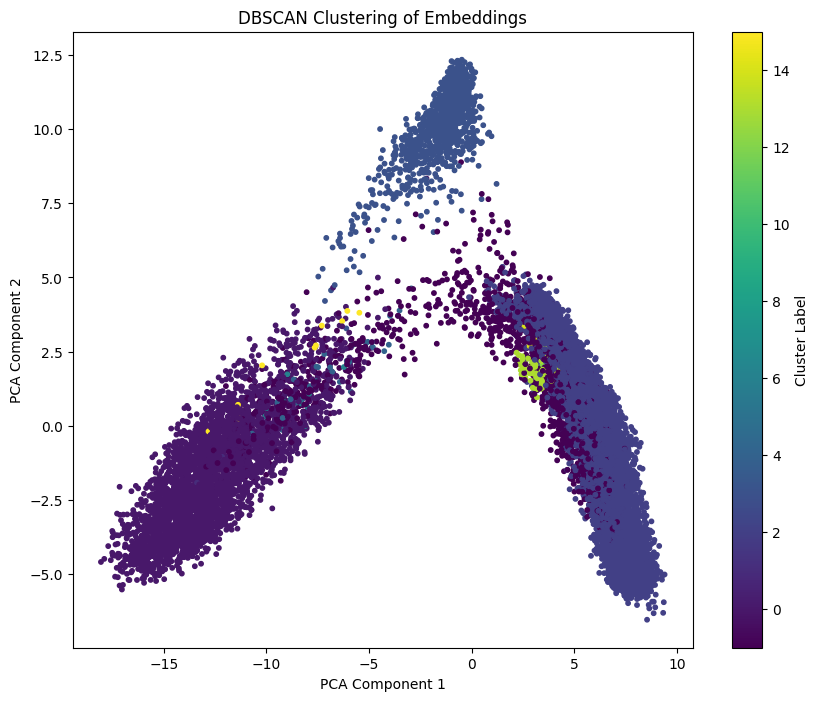

In [ ]:
'''
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

# Reduce dimensions to 2D for visualization
pca = PCA(n_components=2)
reduced_embeddings = pca.fit_transform(embeddings)

# Plot the clusters
plt.figure(figsize=(10, 8))
scatter = plt.scatter(reduced_embeddings[:, 0], reduced_embeddings[:, 1], c=cluster_labels, cmap='viridis', s=10)
plt.colorbar(scatter, label='Cluster Label')
plt.title('DBSCAN Clustering of Embeddings')
plt.xlabel('PCA Component 1')
plt.ylabel('PCA Component 2')
plt.show()
'''

In [ ]:
'''
# K-means Clustering
from sklearn.cluster import KMeans
# Load the embeddings
embeddings_file = 'WSI_patch_embeddings.csv'
df_embeddings = pd.read_csv(embeddings_file)
# Extract the feature columns (assuming embeddings are in the first N columns)
embedding_columns = [col for col in df_embeddings.columns if col.startswith('0') or col.isdigit()]
embeddings = df_embeddings[embedding_columns].values
# Apply K-means
kmeans = KMeans(n_clusters=8, random_state=42)  # Adjust n_clusters as needed
kmeans.fit(embeddings)
# Add cluster labels to the DataFrame
df_embeddings['Cluster'] = kmeans.labels_
# Save the results
df_embeddings.to_csv('WSI_patch_embeddings_with_clusters_kmeans.csv', index=False)
'''

In [ ]:

'''
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import pandas as pd
import tifffile
from PIL import Image
import os
from matplotlib.cm import get_cmap

def overlay_clusters_with_transparency(wsi_folder, metadata_file, output_folder):
    os.makedirs(output_folder, exist_ok=True)
    
    # Load metadata with cluster labels
    metadata_df = pd.read_csv(metadata_file)
    
    # Get a colormap for distinct cluster colors
    cmap = get_cmap('tab20')  # Use a colormap with up to 20 distinct colors
    
    # Iterate over each slide
    for slide_name in metadata_df['Slide_ID'].unique():
        slide_data = metadata_df[metadata_df['Slide_ID'] == slide_name]
        
        # Load the WSI image
        wsi_path = os.path.join(wsi_folder, f"{slide_name}.tif")
        wsi_image = tifffile.imread(wsi_path)
        wsi_image = Image.fromarray(wsi_image)
        
        # Create a plot
        fig, ax = plt.subplots(1, figsize=(224, 224))
        ax.imshow(wsi_image)
        
        # Overlay patches with transparent cluster colors
        for _, row in slide_data.iterrows():
            x, y = row['X'], row['Y']
            cluster = row['Cluster']
            color = cmap(cluster % cmap.N) if cluster != -1 else (0.5, 0.5, 0.5, 0.3)  # Gray for noise
            
            # Add a semi-transparent rectangle
            rect = patches.Rectangle((x, y), 224, 224, linewidth=0, edgecolor=None, facecolor=color, alpha=0.5)
            ax.add_patch(rect)
        
        # Save the overlay image
        output_path = os.path.join(output_folder, f"{slide_name}_cluster_overlay.png")
        plt.title(f"Overlay for {slide_name}")
        plt.axis('off')
        plt.savefig(output_path, bbox_inches='tight')
        plt.close()

# Paths
metadata_file = "WSI_patch_embeddings_with_clusters_kmeans.csv"  # Metadata with cluster labels
output_folder = "outputs/"  # Folder to save overlay images

# Generate transparent overlays
overlay_clusters_with_transparency(wsi_folder, metadata_file, output_folder)
'''

C:\Users\simon\AppData\Local\Temp\ipykernel_72136\2499581968.py:16: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = get_cmap('tab20')  # Use a colormap with up to 20 distinct colors
